In [1]:
# Importar las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
# URL del archivo en el bucket público de AWS
url = "https://hybridge-education-machine-learning-datasets.s3.us-east-1.amazonaws.com/Fraud.csv"
df = pd.read_csv(url)

In [3]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
len(df)

6362620

# ¡¡¡6,362,620 OBSERVACIONES!!!

In [5]:
df.info()
print(df.isnull().sum().sum(), "valores nulos")
print(df["isFraud"].value_counts())
print(df["isFraud"].value_counts(normalize=True))
df.groupby("type")["isFraud"].agg(["sum", "count"])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB
0 valores nulos
isFraud
0    6354407
1       8213
Name: count, dtype: int64
isFraud
0    0.998709
1    0.001291
Name: proportion, dtype: float64


,sum,count
type,,
CASH_IN,0,1399284
CASH_OUT,4116,2237500
DEBIT,0,41432
PAYMENT,0,2151495
TRANSFER,4097,532909


In [6]:
# Solo los tipos donde puede haber fraude
df_model = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()

# Codificar el tipo (1 = TRANSFER, 0 = CASH_OUT)
df_model["type"] = (df_model["type"] == "TRANSFER").astype(int)

# Variables de inconsistencia de saldo (muy informativas en fraude)
df_model["errorOrig"] = df_model["newbalanceOrig"] + df_model["amount"] - df_model["oldbalanceOrg"]
df_model["errorDest"] = df_model["oldbalanceDest"] + df_model["amount"] - df_model["newbalanceDest"]

# nameOrig y nameDest son identificadores: se descartan
# isFlaggedFraud se excluye (es la regla del sistema, no una característica real)
features = ["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig",
            "oldbalanceDest", "newbalanceDest", "errorOrig", "errorDest"]
X = df_model[features]
y = df_model["isFraud"]

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

scaler = StandardScaler().fit(X_train)   # ajustar solo con train
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

In [8]:
modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_train_s, y_train)
y_pred = modelo.predict(X_test_s)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, digits=4))

[[828524    135]
 [  1235   1229]]
              precision    recall  f1-score   support

           0     0.9985    0.9998    0.9992    828659
           1     0.9010    0.4988    0.6421      2464

    accuracy                         0.9984    831123
   macro avg     0.9498    0.7493    0.8206    831123
weighted avg     0.9982    0.9984    0.9981    831123



In [9]:
modelo_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
modelo_bal.fit(X_train_s, y_train)
y_pred_bal = modelo_bal.predict(X_test_s)
print(confusion_matrix(y_test, y_pred_bal))
print(classification_report(y_test, y_pred_bal, digits=4))

[[779751  48908]
 [   278   2186]]
              precision    recall  f1-score   support

           0     0.9996    0.9410    0.9694    828659
           1     0.0428    0.8872    0.0816      2464

    accuracy                         0.9408    831123
   macro avg     0.5212    0.9141    0.5255    831123
weighted avg     0.9968    0.9408    0.9668    831123



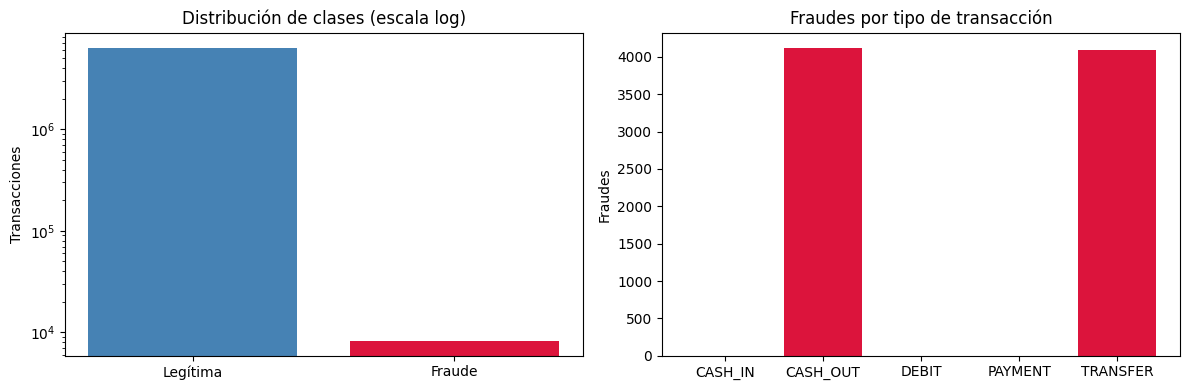

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Clases (escala log por el desbalance)
conteo = df["isFraud"].value_counts().sort_index()
ax[0].bar(["Legítima", "Fraude"], conteo.values, color=["steelblue", "crimson"])
ax[0].set_yscale("log")
ax[0].set_title("Distribución de clases (escala log)")
ax[0].set_ylabel("Transacciones")

# Fraudes por tipo de transacción
fraude_tipo = df.groupby("type")["isFraud"].sum()
ax[1].bar(fraude_tipo.index, fraude_tipo.values, color="crimson")
ax[1].set_title("Fraudes por tipo de transacción")
ax[1].set_ylabel("Fraudes")

plt.tight_layout()
plt.show()

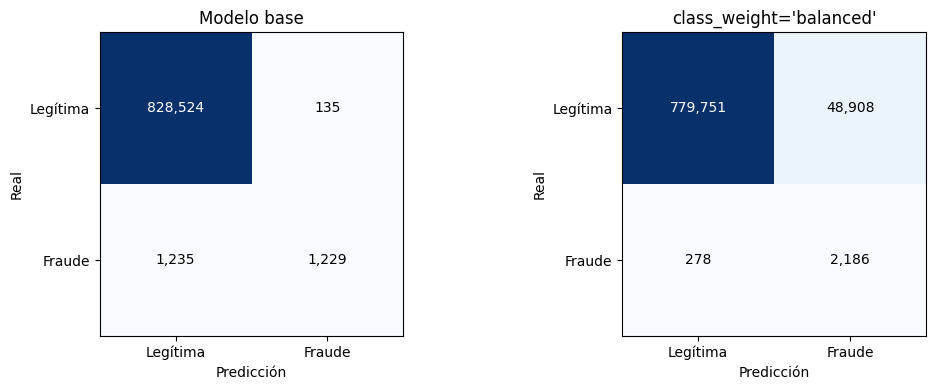

In [11]:
def graficar_matriz(ax, y_real, y_pred, titulo):
    cm = confusion_matrix(y_real, y_pred)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Legítima", "Fraude"])
    ax.set_yticklabels(["Legítima", "Fraude"])
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
    ax.set_title(titulo)
    for i in range(2):
        for j in range(2):
            color = "white" if cm[i, j] > cm.max() / 2 else "black"
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color=color)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
graficar_matriz(ax[0], y_test, y_pred, "Modelo base")
graficar_matriz(ax[1], y_test, y_pred_bal, "class_weight='balanced'")
plt.tight_layout()
plt.show()

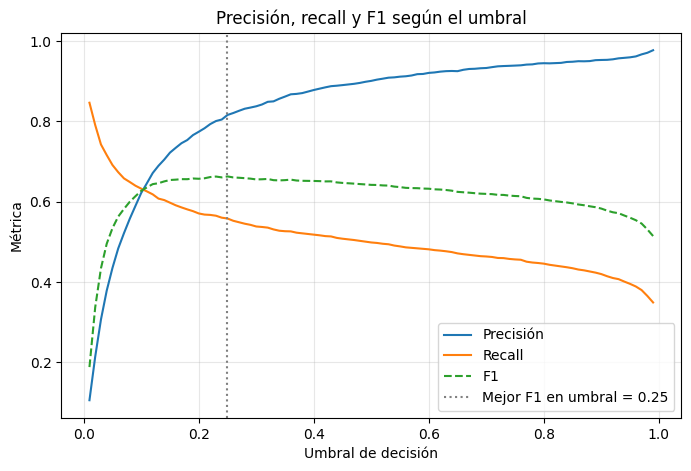

Umbral con mejor F1: 0.25 (precisión=0.816, recall=0.558)


In [12]:
probs = modelo.predict_proba(X_test_s)[:, 1]
y_real = y_test.to_numpy()

umbrales = np.linspace(0.01, 0.99, 99)
precisiones, recalls = [], []

for u in umbrales:
    pred = (probs >= u).astype(int)
    tp = np.sum((pred == 1) & (y_real == 1))
    fp = np.sum((pred == 1) & (y_real == 0))
    fn = np.sum((pred == 0) & (y_real == 1))
    precisiones.append(tp / (tp + fp) if (tp + fp) > 0 else 0)
    recalls.append(tp / (tp + fn))

precisiones, recalls = np.array(precisiones), np.array(recalls)
f1 = 2 * precisiones * recalls / (precisiones + recalls + 1e-12)
mejor = np.argmax(f1)

plt.figure(figsize=(8, 5))
plt.plot(umbrales, precisiones, label="Precisión")
plt.plot(umbrales, recalls, label="Recall")
plt.plot(umbrales, f1, label="F1", linestyle="--")
plt.axvline(umbrales[mejor], color="gray", linestyle=":",
            label=f"Mejor F1 en umbral = {umbrales[mejor]:.2f}")
plt.xlabel("Umbral de decisión")
plt.ylabel("Métrica")
plt.title("Precisión, recall y F1 según el umbral")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Umbral con mejor F1: {umbrales[mejor]:.2f} "
      f"(precisión={precisiones[mejor]:.3f}, recall={recalls[mejor]:.3f})")